# E3: K-Fold spliting experiment (CAMELS trong Caravan)

Thí nghiệm này tương ứng với model **"Global LSTM without static features"** trong Kratzert et al. (2019, WRR), có NSE trung vị 0.63 trên 531 lưu vực CAMELS.

| Thiết lập | Giá trị |
|---|---|
| Đầu vào | 22 biến khí tượng ERA5-Land, có thuộc tính tĩnh |
| Đầu ra | `streamflow` (mm/ngày) của ngày cuối cửa sổ |
| Cửa sổ | 365 ngày, stride 1 |
| Train / Val / Test | 01/10/1980–30/09/1990 / 01/10/1990–30/09/1995 / 01/10/1995–30/09/2010 |
| Model | LSTM 256 cell, dropout 0.4, 1 lớp Linear ở cuối |
| Loss | NSE* (trung bình NSE có trọng số theo từng lưu vực) |

**Các bước trong notebook**

1. Cấu hình chung (**bạn chỉ cần sửa ô này**)
2. Kiểm tra môi trường
3. Chuyển CSV → netCDF (chỉ chạy 1 lần)
4. Kiểm tra chất lượng và chọn lưu vực
5. Tạo file cấu hình NeuralHydrology
6. Train
7. Xem quá trình train, chọn epoch tốt nhất theo tập validation
8. Đánh giá trên tập test
9. Xem hydrograph của một số lưu vực

**Cách dùng:** lần đầu để `QUICK_TEST = True` để chạy thử nhanh (20 lưu vực, 2 epoch, LSTM nhỏ), kiểm tra mọi bước không lỗi. Sau đó đổi `QUICK_TEST = False`, chạy lại từ ô 1 để train thật. Bước 3 không cần chạy lại.

In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
from pathlib import Path

CARAVAN_ROOT = Path(r"D:\Dev\ANCU Project\Caravan-csv")
QUICK_TEST = False

RESULT_DIR = Path("result")
SUBSET = "camels"
SEED = 42

DYNAMIC_INPUTS = [
    "total_precipitation_sum",
    "temperature_2m_min", "temperature_2m_mean", "temperature_2m_max",
    "dewpoint_temperature_2m_min", "dewpoint_temperature_2m_mean", "dewpoint_temperature_2m_max",
    "surface_net_solar_radiation_mean", "surface_net_solar_radiation_max",
    "surface_net_thermal_radiation_min", "surface_net_thermal_radiation_mean", "surface_net_thermal_radiation_max",
    "surface_pressure_min", "surface_pressure_mean", "surface_pressure_max",
    "u_component_of_wind_10m_min", "u_component_of_wind_10m_mean", "u_component_of_wind_10m_max",
    "v_component_of_wind_10m_min", "v_component_of_wind_10m_mean", "v_component_of_wind_10m_max",
    "potential_evaporation_sum_FAO_PENMAN_MONTEITH",
]
TARGET = "streamflow"
STATIC_ATTRIBUTES = [
    # Khí hậu
    "p_mean", "pet_mean_FAO_PM", "aridity_FAO_PM", "seasonality_FAO_PM", "frac_snow",
    "high_prec_freq", "high_prec_dur", "low_prec_freq", "low_prec_dur",
    # Địa hình
    "ele_mt_sav", "slp_dg_sav", "area",
    # Thảm phủ
    "for_pc_sse", "crp_pc_sse", "pst_pc_sse", "urb_pc_sse",
    # Đất
    "cly_pc_sav", "slt_pc_sav", "snd_pc_sav", "soc_th_sav", "swc_pc_syr",
    # Địa chất, nước ngầm
    "kar_pc_sse", "gwt_cm_sav",
    # Hồ và tác động con người
    "lka_pc_sse", "ire_pc_sse", "dor_pc_pva",
]

PERIODS = {
    "train":      ("1980-10-01", "1990-09-30"),
    "validation": ("1990-10-01", "1995-09-30"),
    "test":       ("1995-10-01", "2010-09-30"),
}
SEQ_LENGTH = 365
MIN_VALID_YEARS = {"train": 5, "validation": 2, "test": 3}   # số năm có nhãn tối thiểu để giữ lưu vực
MODEL = 'gru'
model_tag = {"cudalstm": "lstm"}.get(MODEL, MODEL)
# Siêu tham số
if QUICK_TEST:
    EXPERIMENT = "e3_" + model_tag +"_forcing_only_QUICK"
    N_BASINS_QUICK = 20
    HIDDEN_SIZE, EPOCHS = 32, 2
    LEARNING_RATE = {0: 1e-3}
else:
    EXPERIMENT = "e3_" + model_tag +"static_forcing"
    EPOCHS = 5
    HIDDEN_SIZE = 256
    D_MODEL, N_HEADS, N_LAYERS, DIM_FF = 64, 4, 4,256
    LEARNING_RATE = {0: 1e-3} if MODEL != "transformer" else {0: 1e-4}                       # trong nhánh QUICK_TEST
    LEARNING_RATE = ({0: 1e-3, 10: 5e-4, 25: 1e-4} if MODEL != "transformer"
                 else {0: 1e-4, 10: 5e-5, 25: 1e-5})                                      # trong nhánh train thật
BATCH_SIZE = 256 if MODEL != "transformer" else 128
OUTPUT_DROPOUT = 0.4 if MODEL != "transformer" else 0.1

CSV_DIR = CARAVAN_ROOT / "timeseries" / "csv" / SUBSET
NC_DIR = CARAVAN_ROOT / "timeseries" / "netcdf" / SUBSET
E3_DIR = RESULT_DIR / "e3"
E3_DIR.mkdir(parents=True, exist_ok=True)

N_FOLDS = 12
FOLD_SEED = 42
FOLDS_TO_RUN = [1, 2] if QUICK_TEST else list(range(1, N_FOLDS + 1))

print("CSV:", CSV_DIR, "| ton tai:", CSV_DIR.is_dir())
print("Ket qua se luu tai:", E3_DIR.resolve())
if QUICK_TEST:
    print("\n*** QUICK_TEST = True: day chi la lan chay thu, KHONG phai ket qua that ***")

CSV: D:\Dev\ANCU Project\Caravan-csv\timeseries\csv\camels | ton tai: True
Ket qua se luu tai: D:\Dev\ANCU Project\main\src\result\e3


In [3]:
import sys, platform, importlib
import numpy as np
import pandas as pd
import torch

print("OS:", platform.platform(), "| Python:", sys.version.split()[0])
for pkg in ["torch", "neuralhydrology", "pandas", "numpy", "xarray", "netCDF4"]:
    m = importlib.import_module(pkg)
    print(f"  {pkg}: {getattr(m, '__version__', 'installed')}")

if torch.cuda.is_available():
    DEVICE = "cuda:0"
    x = torch.randn(1024, 1024, device=DEVICE); _ = (x @ x).sum().item()
    print("GPU:", torch.cuda.get_device_name(0), "| CUDA", torch.version.cuda, "-> OK")
else:
    DEVICE = "cpu"
    print("KHONG thay GPU, se chay tren CPU (rat cham). Kiem tra lai ban PyTorch.")

OS: Windows-10-10.0.26200-SP0 | Python: 3.11.17
  torch: 2.11.0+cu128
  neuralhydrology: installed
  pandas: 3.0.6
  numpy: 2.4.6
  xarray: 2026.9.0
  netCDF4: 1.7.5
GPU: NVIDIA GeForce RTX 5060 Ti | CUDA 12.8 -> OK


In [4]:
import xarray as xr
from tqdm import tqdm
from neuralhydrology.datasetzoo.caravan import load_caravan_attributes

warmup_start = pd.Timestamp(PERIODS["train"][0]) - pd.Timedelta(days=SEQ_LENGTH - 1)
test_end = pd.Timestamp(PERIODS["test"][1])

rows = []
for nc in tqdm(sorted(NC_DIR.glob("*.nc")), desc="Kiem tra luu vuc"):
    with xr.open_dataset(nc) as ds:
        df = ds[DYNAMIC_INPUTS + [TARGET]].to_dataframe()
    rec = {"gauge_id": nc.stem}
    for p, (s, e) in PERIODS.items():
        rec[f"{p}_years"] = round(df.loc[s:e, TARGET].notna().sum() / 365.25, 2)
    rec["forcing_nan_days"] = int(df.loc[warmup_start:test_end, DYNAMIC_INPUTS].isna().any(axis=1).sum())
    rec["forcing_covers_period"] = bool(df.index.min() <= warmup_start and df.index.max() >= test_end)
    rows.append(rec)

qc = pd.DataFrame(rows).set_index("gauge_id")
reasons = []
for gid, r in qc.iterrows():
    why = [f"{p}<{MIN_VALID_YEARS[p]}nam" for p in PERIODS if r[f"{p}_years"] < MIN_VALID_YEARS[p]]
    if r.forcing_nan_days > 0: why.append(f"forcing thieu {r.forcing_nan_days} ngay")
    if not r.forcing_covers_period: why.append("forcing khong du dai")
    reasons.append("; ".join(why))
qc["exclude_reason"] = reasons
qc["selected"] = qc["exclude_reason"] == ""
qc.to_csv(E3_DIR / "basin_qc.csv")

selected = qc.index[qc.selected].tolist()
print(f"Tong: {len(qc)} luu vuc | Giu lai: {len(selected)} | Loai: {(~qc.selected).sum()}")
print(qc[[f"{p}_years" for p in PERIODS]].describe().round(2).loc[["min", "50%", "max"]])
if (~qc.selected).any():
    print("\nCac luu vuc bi loai:")
    print(qc.loc[~qc.selected, "exclude_reason"].to_string())

if QUICK_TEST:
    rng = np.random.default_rng(SEED)
    selected = sorted(rng.choice(selected, size=min(N_BASINS_QUICK, len(selected)), replace=False).tolist())
    print(f"\nQUICK_TEST: chi dung {len(selected)} luu vuc")


attrs = load_caravan_attributes(CARAVAN_ROOT, subdataset=SUBSET)
missing_cols = [a for a in STATIC_ATTRIBUTES if a not in attrs.columns]
if missing_cols:
    raise ValueError(f"Khong tim thay cac thuoc tinh static: {missing_cols}")
attrs = attrs.loc[attrs.index.intersection(selected), STATIC_ATTRIBUTES]

no_attr = sorted(set(selected) - set(attrs.index))
has_nan = attrs.index[attrs.isna().any(axis=1)].tolist()
zero_std = [a for a in STATIC_ATTRIBUTES if attrs[a].std() == 0]
print(f"Thuoc tinh tinh: {len(STATIC_ATTRIBUTES)} | luu vuc thieu thuoc tinh: {len(no_attr)} "
      f"| co NaN: {len(has_nan)} | thuoc tinh co std = 0: {zero_std}")
if zero_std:
    raise ValueError(f"Bo cac thuoc tinh khong doi nay khoi STATIC_ATTRIBUTES: {zero_std}")

selected = [b for b in selected if b not in set(no_attr) | set(has_nan)]

# ---- Chia 12 fold theo lưu vực (chỉ chia 1 lần, các phiên sau dùng lại) ----
FOLDS_FILE = E3_DIR / "folds.csv"
if FOLDS_FILE.exists():
    folds = pd.read_csv(FOLDS_FILE, dtype={"basin": str}).set_index("basin")["fold"]
    if set(folds.index) != set(selected):
        raise ValueError("Danh sach luu vuc khac voi lan chia fold truoc. Xoa folds.csv neu muon chia lai.")
    print("Dung lai cach chia fold da luu:", FOLDS_FILE)
else:
    rng = np.random.default_rng(FOLD_SEED)
    shuffled = rng.permutation(sorted(selected))
    folds = pd.Series({b: i % N_FOLDS + 1 for i, b in enumerate(shuffled)}, name="fold")
    folds.index.name = "basin"
    folds.to_csv(FOLDS_FILE)
    print("Da chia fold va luu vao:", FOLDS_FILE)
print("So luu vuc moi fold:", folds.value_counts().sort_index().to_dict())

def fold_dir(k):
    return E3_DIR / f"fold_{k:02d}"

for k in range(1, N_FOLDS + 1):
    d = fold_dir(k)
    d.mkdir(exist_ok=True)
    (d / "train_basins.txt").write_text("\n".join(sorted(folds.index[(folds != k).values])))
    (d / "test_basins.txt").write_text("\n".join(sorted(folds.index[(folds == k).values])))

attrs.loc[selected].describe().T.round(3).to_csv(E3_DIR / "static_attributes_summary.csv")
print(f"Con lai {len(selected)} luu vuc")

Kiem tra luu vuc: 100%|██████████| 671/671 [06:03<00:00,  1.85it/s]

Tong: 671 luu vuc | Giu lai: 638 | Loai: 33
     train_years  validation_years  test_years
min         1.00               4.0        11.0
50%         9.75               5.0        15.0
max        10.00               5.0        15.0

Cac luu vuc bi loai:
gauge_id
camels_01350080    train<5nam
camels_01594950    train<5nam
camels_02096846    train<5nam
camels_02193340    train<5nam
camels_02198100    train<5nam
camels_02215100    train<5nam
camels_02363000    train<5nam
camels_02427250    train<5nam
camels_02464360    train<5nam
camels_03050000    train<5nam
camels_03338780    train<5nam
camels_04115265    train<5nam
camels_04213075    train<5nam
camels_05062500    train<5nam
camels_05592575    train<5nam
camels_06188000    train<5nam
camels_06221400    train<5nam
camels_06440200    train<5nam
camels_06906800    train<5nam
camels_06934000    train<5nam
camels_07263295    train<5nam
camels_07359610    train<5nam
camels_07362587    train<5nam
camels_08155200    train<5nam
camels_09107000  

In [5]:
fmt = lambda d: pd.Timestamp(d).strftime("%d/%m/%Y")
lr_yaml = "\n".join(f"  {k}: {v}" for k, v in LEARNING_RATE.items())
inputs_yaml = "\n".join(f"  - {v}" for v in DYNAMIC_INPUTS)

if MODEL == "cudalstm":
    model_lines = [
        "model: cudalstm",
        "head: regression",
        "output_activation: linear",
        f"hidden_size: {HIDDEN_SIZE}",
        "initial_forget_bias: 3",
        f"output_dropout: {OUTPUT_DROPOUT}",
    ]
elif MODEL == "gru":
    model_lines = [
        "model: gru",
        "head: regression",
        "output_activation: linear",
        f"hidden_size: {HIDDEN_SIZE}",
        f"output_dropout: {OUTPUT_DROPOUT}",
    ]
else:
    model_lines = [
        "model: transformer",
        "head: regression",
        "output_activation: linear",
        "dynamics_embedding:",
        "  type: fc",
        f"  hiddens: [{D_MODEL}]",
        "  activation: tanh",
        "  dropout: 0.0",
        f"transformer_nlayers: {N_LAYERS}",
        f"transformer_nheads: {N_HEADS}",
        f"transformer_dim_feedforward: {DIM_FF}",
        "transformer_dropout: 0.1",
        "transformer_positional_encoding_type: sum",
        "transformer_positional_dropout: 0.0",
        f"output_dropout: {OUTPUT_DROPOUT}",
    ]
model_yaml = "\n".join(model_lines)
static_yaml = "static_attributes:\n" + "\n".join(f"  - {a}" for a in STATIC_ATTRIBUTES)
CONFIG_TEMPLATE = f"""# --- Thi nghiem ---
experiment_name: __EXPERIMENT__
run_dir: __RUN_DIR__
seed: {SEED}
device: {DEVICE}

# --- Luu vuc va moc chia (A) ---
train_basin_file: __TRAIN_BASINS__
validation_basin_file: __TRAIN_BASINS__
test_basin_file: __TEST_BASINS__
train_start_date: {fmt(PERIODS['train'][0])}
train_end_date: {fmt(PERIODS['train'][1])}
validation_start_date: {fmt(PERIODS['validation'][0])}
validation_end_date: {fmt(PERIODS['validation'][1])}
test_start_date: {fmt(PERIODS['test'][0])}
test_end_date: {fmt(PERIODS['test'][1])}

# --- Du lieu ---
dataset: caravan
data_dir: {CARAVAN_ROOT.resolve().as_posix()}
dynamic_inputs:
{inputs_yaml}
target_variables:
  - {TARGET}
clip_targets_to_zero:
  - {TARGET}
{static_yaml}

# --- Cua so truot ---
seq_length: {SEQ_LENGTH}
predict_last_n: 1

# --- Model ---
{model_yaml}

# --- Train ---
optimizer: Adam
loss: NSE
learning_rate:
{lr_yaml}
batch_size: {BATCH_SIZE}
epochs: {EPOCHS}
clip_gradient_norm: 1
num_workers: 0

# --- Danh gia ---
validate_every: 1
metrics:
  - NSE
  - KGE
  - Alpha-NSE
  - Beta-NSE
  - Pearson-r
  - FHV
  - FLV

# --- Log ---
log_interval: 5
log_tensorboard: False
log_n_figures: 0
save_weights_every: 1
"""
def make_config(k: int) -> Path:
    d = fold_dir(k)
    text = (CONFIG_TEMPLATE
            .replace("__EXPERIMENT__", f"{EXPERIMENT}_fold{k:02d}")
            .replace("__RUN_DIR__", (d / "runs").resolve().as_posix())
            .replace("__TRAIN_BASINS__", (d / "train_basins.txt").resolve().as_posix())
            .replace("__TEST_BASINS__", (d / "test_basins.txt").resolve().as_posix()))
    path = d / f"{EXPERIMENT}_fold{k:02d}.yml"
    path.write_text(text, encoding="utf-8")
    return path

print(make_config(1).read_text(encoding="utf-8"))   # xem thử cấu hình của fold 1

# --- Thi nghiem ---
experiment_name: e3_grustatic_forcing_fold01
run_dir: D:/Dev/ANCU Project/main/src/result/e3/fold_01/runs
seed: 42
device: cuda:0

# --- Luu vuc va moc chia (A) ---
train_basin_file: D:/Dev/ANCU Project/main/src/result/e3/fold_01/train_basins.txt
validation_basin_file: D:/Dev/ANCU Project/main/src/result/e3/fold_01/train_basins.txt
test_basin_file: D:/Dev/ANCU Project/main/src/result/e3/fold_01/test_basins.txt
train_start_date: 01/10/1980
train_end_date: 30/09/1990
validation_start_date: 01/10/1990
validation_end_date: 30/09/1995
test_start_date: 01/10/1995
test_end_date: 30/09/2010

# --- Du lieu ---
dataset: caravan
data_dir: D:/Dev/ANCU Project/Caravan-csv
dynamic_inputs:
  - total_precipitation_sum
  - temperature_2m_min
  - temperature_2m_mean
  - temperature_2m_max
  - dewpoint_temperature_2m_min
  - dewpoint_temperature_2m_mean
  - dewpoint_temperature_2m_max
  - surface_net_solar_radiation_mean
  - surface_net_solar_radiation_max
  - surface_net_thermal_rad

In [6]:
import json, logging, re, time
from neuralhydrology.nh_run import start_run, eval_run

def reset_nh_logging():
    """Bắt buộc trước mỗi start_run: nếu không, log của fold sau bị ghi vào output.log của fold đầu."""
    root = logging.getLogger()
    for h in list(root.handlers):
        root.removeHandler(h)
        h.close()

def best_epoch_from_log(run_dir):
    """Epoch có NSE trung vị validation cao nhất, trong số các epoch đã lưu trọng số."""
    nse = {}
    for line in (run_dir / "output.log").read_text(encoding="utf-8").splitlines():
        m = re.search(r"Epoch (\d+) average validation loss: .*?, NSE: (-?[\d.]+|nan)", line)
        if m:
            nse[int(m.group(1))] = float(m.group(2))
    saved = {int(p.stem[-3:]) for p in run_dir.glob("model_epoch*.pt")}
    nse = {e: v for e, v in nse.items() if e in saved and not np.isnan(v)}
    return max(nse, key=nse.get), nse

for k in FOLDS_TO_RUN:
    d = fold_dir(k)
    if (d / "done.json").exists():
        print(f"Fold {k:02d}: da xong, bo qua")
        continue

    print(f"\n==================== FOLD {k:02d}/{N_FOLDS} ====================")
    t0 = time.time()
    cfg_path = make_config(k)
    runs_dir = d / "runs"
    before = set(runs_dir.glob("*")) if runs_dir.exists() else set()

    reset_nh_logging()
    start_run(config_file=cfg_path)
    run_dir = sorted(set(runs_dir.glob("*")) - before, key=lambda p: p.stat().st_mtime)[-1]

    # Chọn epoch theo validation (lưu vực train, 1990-1995), rồi test trên lưu vực CHƯA THẤY (1995-2010)
    best, val_nse = best_epoch_from_log(run_dir)
    eval_run(run_dir=run_dir, period="test", epoch=best)

    m = pd.read_csv(run_dir / "test" / f"model_epoch{best:03d}" / "test_metrics.csv",
                    dtype={"basin": str}).set_index("basin")
    m.insert(0, "fold", k)
    m.to_csv(d / "test_metrics.csv")

    minutes = round((time.time() - t0) / 60, 1)
    (d / "done.json").write_text(json.dumps(
        {"run_dir": str(run_dir.resolve()), "best_epoch": best, "val_nse": val_nse, "minutes": minutes}, indent=2))
    print(f"Fold {k:02d} xong: epoch {best} | NSE trung vi test = {m['NSE'].median():.3f} | {minutes} phut")

Fold 01: da xong, bo qua
Fold 02: da xong, bo qua
Fold 03: da xong, bo qua
Fold 04: da xong, bo qua
Fold 05: da xong, bo qua
Fold 06: da xong, bo qua

==================== FOLD 07/12 ====================
2026-10-26 10:35:39,822: Logging to D:\Dev\ANCU Project\main\src\result\e3\fold_07\runs\e3_grustatic_forcing_fold07_2610_103539\output.log initialized.
2026-10-26 10:35:39,824: ### Folder structure created at D:\Dev\ANCU Project\main\src\result\e3\fold_07\runs\e3_grustatic_forcing_fold07_2610_103539
2026-10-26 10:35:39,824: ### Run configurations for e3_grustatic_forcing_fold07
2026-10-26 10:35:39,824: experiment_name: e3_grustatic_forcing_fold07
2026-10-26 10:35:39,825: run_dir: D:\Dev\ANCU Project\main\src\result\e3\fold_07\runs\e3_grustatic_forcing_fold07_2610_103539
2026-10-26 10:35:39,825: seed: 42
2026-10-26 10:35:39,825: device: cuda:0
2026-10-26 10:35:39,826: train_basin_file: D:\Dev\ANCU Project\main\src\result\e3\fold_07\train_basins.txt
2026-10-26 10:35:39,826: validation_ba

Da xong 3/12 fold: [1, 2, 3]
              NSE    KGE  Alpha-NSE  Beta-NSE  Pearson-r     FHV           FLV  n_luu_vuc  n_NSE_am
trung_vi    0.429  0.449      0.629    -0.063      0.717 -36.185 -4.126900e+01        161        13
trung_binh  0.265  0.329      0.648    -0.044      0.673 -33.626 -4.251351e+10        161        13

NSE trung vi theo fold: {1: 0.377, 2: 0.504, 3: 0.412}

So sanh tren 161 luu vuc: {'E2 (đã thấy lưu vực)': np.float64(0.516), 'E3 (chưa thấy lưu vực)': np.float64(0.429)} | paper: 0.74 (da thay) vs 0.69 (chua thay)


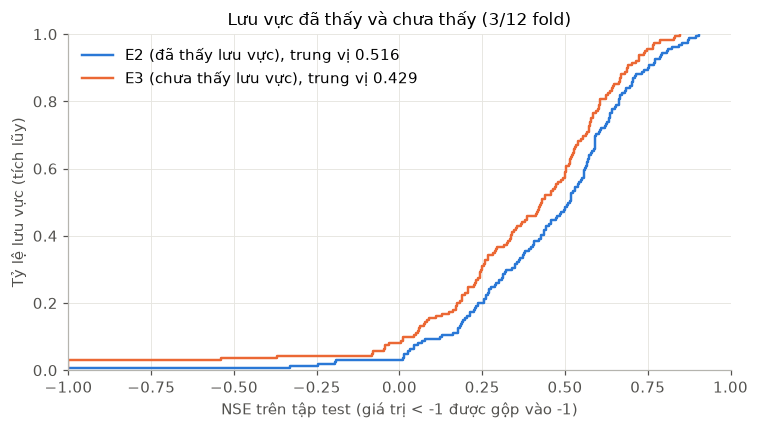

In [9]:
import re
import matplotlib.pyplot as plt

# Màu và kiểu đường thống nhất cho mọi biểu đồ
C_BLUE, C_ORANGE, C_INK, C_MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.labelcolor": C_MUTED, "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.titlesize": 11, "lines.linewidth": 1.6, "legend.frameon": False,
})

done = [k for k in range(1, N_FOLDS + 1) if (fold_dir(k) / "done.json").exists()]
print(f"Da xong {len(done)}/{N_FOLDS} fold: {done}")

e3 = pd.concat([pd.read_csv(fold_dir(k) / "test_metrics.csv", dtype={"basin": str}).set_index("basin")
                for k in done])
e3.to_csv(E3_DIR / f"{EXPERIMENT}_all_folds_test_metrics.csv")

summary = pd.DataFrame({"trung_vi": e3.median(numeric_only=True),
                        "trung_binh": e3.mean(numeric_only=True)}).T.drop(columns="fold")
summary["n_luu_vuc"] = len(e3)
summary["n_NSE_am"] = int((e3["NSE"] < 0).sum())
summary.to_csv(E3_DIR / f"{EXPERIMENT}_test_summary.csv")
print(summary.round(3).to_string())
print("\nNSE trung vi theo fold:", e3.groupby("fold")["NSE"].median().round(3).to_dict())

# ---- So sánh với E2: cùng lưu vực, cùng giai đoạn test; E2 đã thấy lưu vực, E3 chưa thấy ----
E2_METRICS = Path("result/e2/e2_grustatic_forcing_test_metrics.csv")   # sửa đúng tên file E2 của bạn
e2 = pd.read_csv(E2_METRICS, dtype={"basin": str}).set_index("basin")
cmp = pd.DataFrame({"E2 (đã thấy lưu vực)": e2["NSE"], "E3 (chưa thấy lưu vực)": e3["NSE"]}).dropna()
print(f"\nSo sanh tren {len(cmp)} luu vuc:",
      {c: round(cmp[c].median(), 3) for c in cmp.columns}, "| paper: 0.74 (da thay) vs 0.69 (chua thay)")

fig, ax = plt.subplots(figsize=(7, 4))
for col, color in zip(cmp.columns, [C_BLUE, C_ORANGE]):
    x = np.sort(cmp[col].clip(lower=-1).values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=color,
            label=f"{col}, trung vị {cmp[col].median():.3f}")
ax.set_xlim(-1, 1); ax.set_ylim(0, 1)
ax.set_xlabel("NSE trên tập test (giá trị < -1 được gộp vào -1)"); ax.set_ylabel("Tỷ lệ lưu vực (tích lũy)")
ax.set_title(f"Lưu vực đã thấy và chưa thấy ({len(done)}/{N_FOLDS} fold)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(E3_DIR / f"{EXPERIMENT}_E2_vs_E3_cdf.png", dpi=150); plt.show()